# Phi-Psi & Local Bend Analysis — MUC2 Long PTS (3 Systems)

**Strategy:**
1. Ramachandran (φ/ψ) scatter from mean structures (Part A)
2. Virtual Cα bond-angle bend profile per glycoform (Part B)
3. Check total bend vs. overall chain dimensions (Part C)
4. Correlate per-residue bend against PC2 scores (Part D — redistribution test)
5. Compute local twist (Cα dihedral) and correlate with PC2 (Part E — twist hypothesis)


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import warnings
warnings.filterwarnings('ignore')

# ── Colour scheme (consistent with other notebooks) ──────────────────────────
CLR_NOG = '#A23B72'
CLR_GLY = '#2E86AB'
CLR_EXT = '#F18F01'

# ── Paths ─────────────────────────────────────────────────────────────────────
BASE     = '/home/computer2/analysis_simulations/analysis/'
CURV_DIR = BASE + 'radius_of_curvature/'
EXT_DIR  = BASE + 'curvature_xglyc/'
MEAN_DIR = BASE + 'dihedral_angles_15structures_mean_structure/'
EXT_MEAN = BASE + 'mean_3_sytems_glycans_included/'
PCA_FILE = BASE + 'pca_combined/pca_coords_justlongpts.dat'   # PC1 PC2 system
OUT_DIR  = BASE + 'phi_psi_bend_plots/'
os.makedirs(OUT_DIR, exist_ok=True)

# Residue offset (MUC2 numbering starts at 1377)
RES_OFFSET = 1377
GLYCAN_RES = np.array([
    1379,1383,1386,1389,1393,1397,1402,1406,1409,1412,
    1416,1420,1425,1429,1432,1435,1439,1443,1448,1452,
    1455,1458,1462,1466,1471,1475,1478,1481,1485,1489
])

print('Ready. Output dir:', OUT_DIR)

Ready. Output dir: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/


---
## Part A — Ramachandran Scatter from Mean Structures
Parse φ/ψ angles from the mean PDB files using pure NumPy (no mdtraj required).
Each point = one residue.

In [2]:
def parse_ca_from_pdb(pdb_path):
    """Return (residue_numbers, xyz) for all Cα atoms in a PDB."""
    resnums, coords = [], []
    with open(pdb_path) as f:
        for line in f:
            if line[:4] in ('ATOM', 'HETA') and line[12:16].strip() == 'CA':
                resnum = int(line[22:26])
                x = float(line[30:38])
                y = float(line[38:46])
                z = float(line[46:54])
                resnums.append(resnum)
                coords.append([x, y, z])
    return np.array(resnums), np.array(coords)

def parse_n_c_from_pdb(pdb_path):
    """Return dict[resnum] = {'N': xyz, 'CA': xyz, 'C': xyz}."""
    atoms = {}
    with open(pdb_path) as f:
        for line in f:
            if line[:4] != 'ATOM':
                continue
            aname  = line[12:16].strip()
            resnum = int(line[22:26])
            if aname not in ('N', 'CA', 'C'):
                continue
            xyz = np.array([float(line[30:38]), float(line[38:46]), float(line[46:54])])
            atoms.setdefault(resnum, {})[aname] = xyz
    return atoms

def dihedral(p0, p1, p2, p3):
    """Compute dihedral angle (degrees) for four points."""
    b1 = p1 - p0
    b2 = p2 - p1
    b3 = p3 - p2
    n1 = np.cross(b1, b2)
    n2 = np.cross(b2, b3)
    n1 /= np.linalg.norm(n1) + 1e-12
    n2 /= np.linalg.norm(n2) + 1e-12
    m1  = np.cross(n1, b2 / (np.linalg.norm(b2) + 1e-12))
    x   = np.dot(n1, n2)
    y   = np.dot(m1, n2)
    return np.degrees(np.arctan2(y, x))

def compute_phi_psi(pdb_path):
    """Return arrays (phi_deg, psi_deg, residue_numbers) for interior residues."""
    atoms   = parse_n_c_from_pdb(pdb_path)
    resnums = sorted(atoms.keys())
    phis, psis, res = [], [], []
    for i in range(1, len(resnums) - 1):
        r_prev = resnums[i-1]
        r_curr = resnums[i]
        r_next = resnums[i+1]
        d = atoms[r_curr]
        if not all(k in d for k in ('N','CA','C')):
            continue
        if 'C' not in atoms.get(r_prev, {}):
            continue
        if 'N' not in atoms.get(r_next, {}):
            continue
        phi = dihedral(atoms[r_prev]['C'], d['N'],  d['CA'], d['C'])
        psi = dihedral(d['N'], d['CA'], d['C'], atoms[r_next]['N'])
        phis.append(phi); psis.append(psi); res.append(r_curr)
    return np.array(phis), np.array(psis), np.array(res)

# Compute for all three systems
systems_pdb = [
    ('Non-glycosylated', MEAN_DIR + 'noglycans_mean.pdb',      CLR_NOG),
    ('Mid-level Glyc.',  MEAN_DIR + 'glycans_mean.pdb',        CLR_GLY),
    ('Ext. Glyc.',       EXT_MEAN  + 'ext_glycans_struct1.pdb', CLR_EXT),
]

rama_data = {}
for name, pdb, clr in systems_pdb:
    phi, psi, res = compute_phi_psi(pdb)
    rama_data[name] = (phi, psi, res, clr)
    print(f'{name}: {len(phi)} residues with φ/ψ')

Non-glycosylated: 113 residues with φ/ψ
Mid-level Glyc.: 113 residues with φ/ψ
Ext. Glyc.: 114 residues with φ/ψ


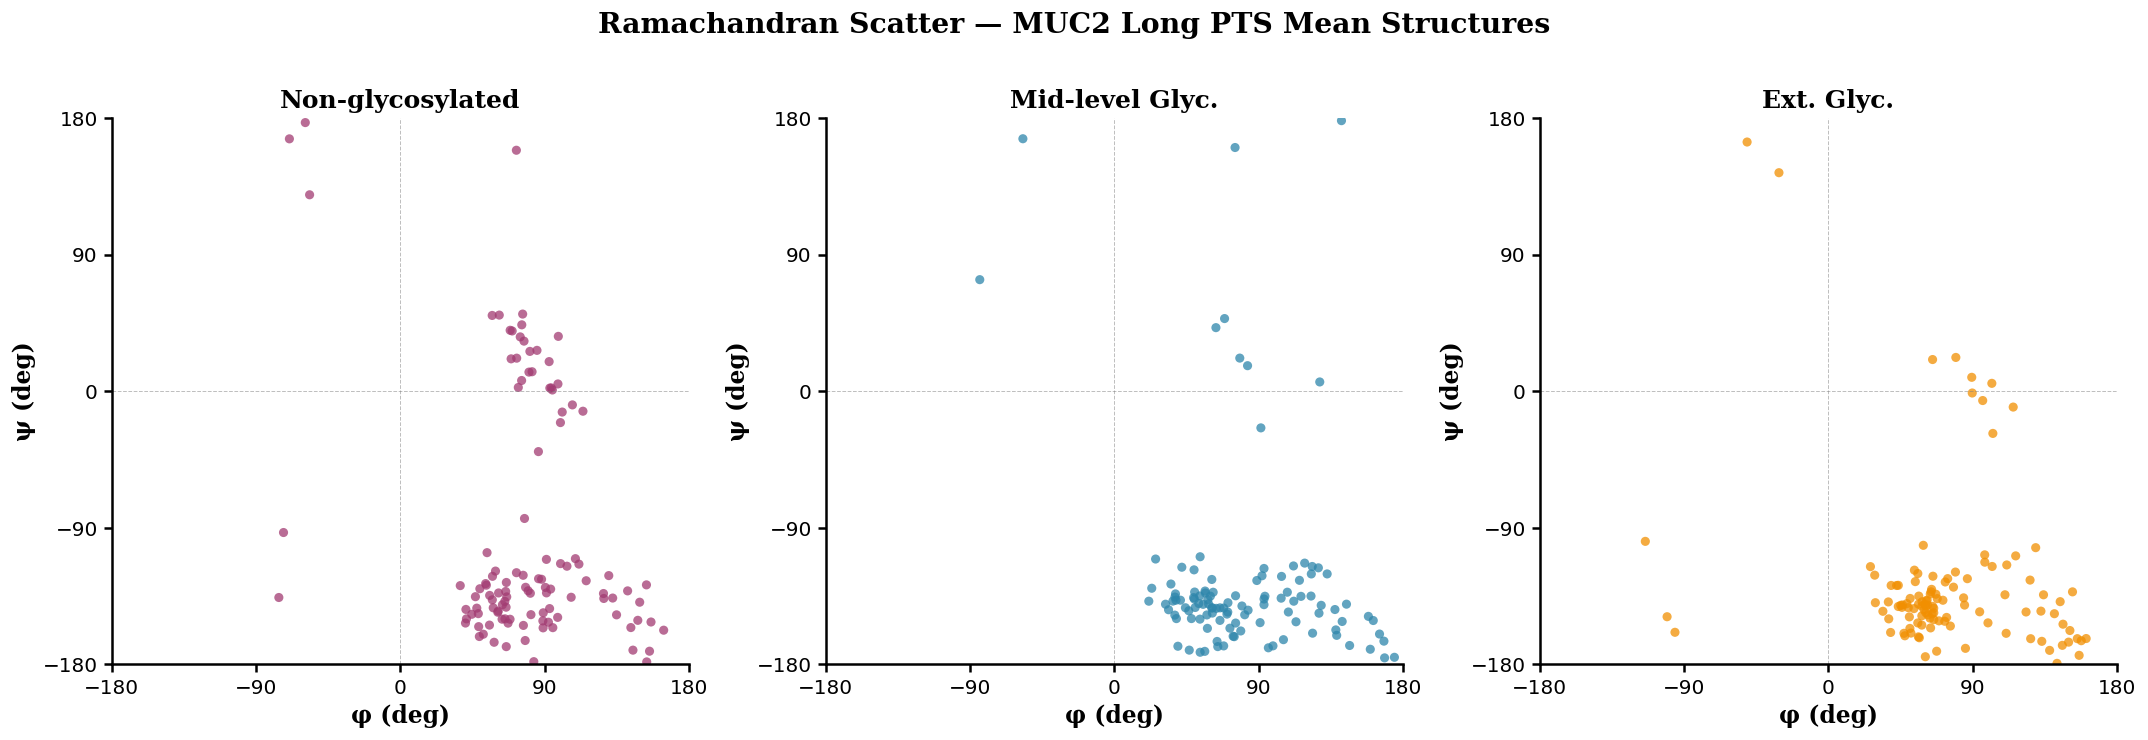

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/ramachandran_3sys.png


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=120)
fig.set_facecolor('white')

for ax, (name, pdb, clr) in zip(axes, systems_pdb):
    phi, psi, res, clr = rama_data[name]
    ax.scatter(phi, psi, c=clr, s=30, alpha=0.75, edgecolors='none')
    ax.axhline(0, color='grey', linewidth=0.6, linestyle='--', alpha=0.5)
    ax.axvline(0, color='grey', linewidth=0.6, linestyle='--', alpha=0.5)
    ax.set_xlim(-180, 180); ax.set_ylim(-180, 180)
    ax.set_xlabel('φ (deg)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
    ax.set_ylabel('ψ (deg)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
    ax.set_title(name, fontsize=15, fontname='DejaVu Serif', fontweight='bold')
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)
    ax.tick_params(labelsize=12, length=5, width=1.5)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_yticks([-180, -90, 0, 90, 180])

fig.suptitle('Ramachandran Scatter — MUC2 Long PTS Mean Structures',
             fontsize=17, fontname='DejaVu Serif', fontweight='bold', y=1.02)
plt.tight_layout()
out = OUT_DIR + 'ramachandran_3sys.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)

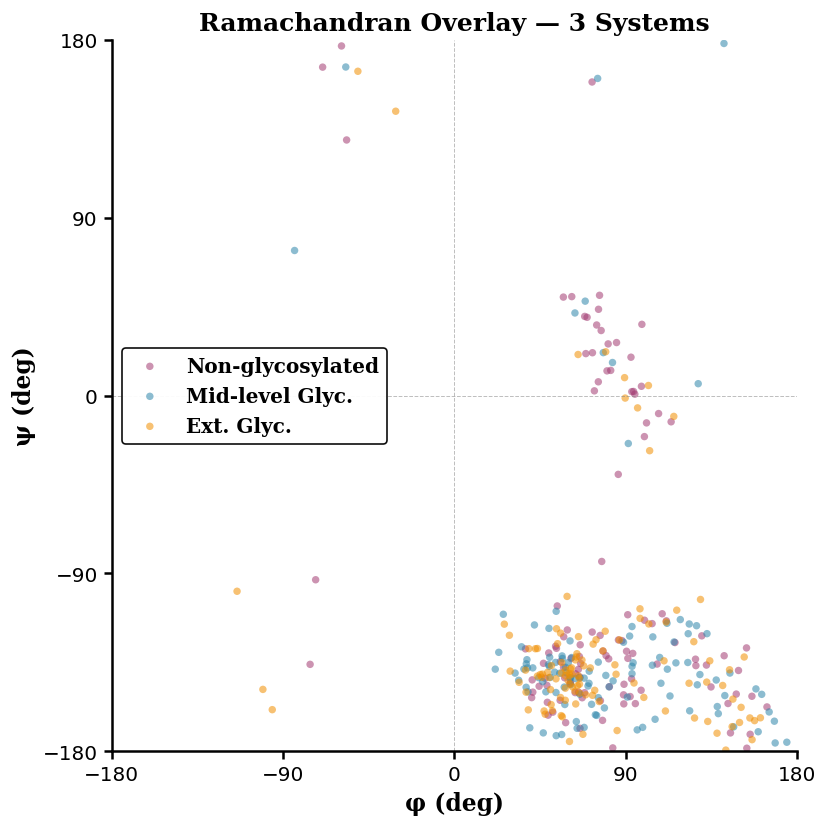

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/ramachandran_overlay.png


In [4]:
# Overlay Ramachandran — all three on one plot
fig, ax = plt.subplots(figsize=(7, 7), dpi=120)
fig.set_facecolor('white')
for name, pdb, clr in systems_pdb:
    phi, psi, res, clr = rama_data[name]
    ax.scatter(phi, psi, c=clr, s=20, alpha=0.55, edgecolors='none', label=name)
ax.axhline(0, color='grey', linewidth=0.6, linestyle='--', alpha=0.5)
ax.axvline(0, color='grey', linewidth=0.6, linestyle='--', alpha=0.5)
ax.set_xlim(-180, 180); ax.set_ylim(-180, 180)
ax.set_xlabel('φ (deg)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
ax.set_ylabel('ψ (deg)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
ax.set_title('Ramachandran Overlay — 3 Systems', fontsize=15,
             fontname='DejaVu Serif', fontweight='bold')
ax.legend(fontsize=12, framealpha=0.95, edgecolor='black',
          prop={'family':'DejaVu Serif','size':12,'weight':'bold'})
ax.set_facecolor('white')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)
ax.tick_params(labelsize=12, length=5, width=1.5)
ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_yticks([-180, -90, 0, 90, 180])
plt.tight_layout()
out = OUT_DIR + 'ramachandran_overlay.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)

---
## Part B — Per-Residue Bend Profile
Load already-computed Cα virtual bond-angle curvature profiles.
`kappa_rms_deg` ≈ 180° – θ (bend angle), so larger = more kinked.
Compare the three glycoforms side by side.

In [5]:
nog_prof = np.genfromtxt(CURV_DIR + 'curvature_profile_noglycans.dat', comments='#')
gly_prof = np.genfromtxt(CURV_DIR + 'curvature_profile_glycans.dat',   comments='#')
ext_prof = np.genfromtxt(EXT_DIR  + 'curvature_profile_xglyc.dat',     comments='#')

# Columns: residue_index, kappa_rms_rad, kappa_se_rad, kappa_rms_deg, kappa_se_deg
res_idx   = nog_prof[:, 0].astype(int) + RES_OFFSET  # MUC2 residue numbers
bend_nog  = nog_prof[:, 3]   # kappa_rms_deg
se_nog    = nog_prof[:, 4]
bend_gly  = gly_prof[:, 3]
se_gly    = gly_prof[:, 4]
bend_ext  = ext_prof[:, 3]
se_ext    = ext_prof[:, 4]

print(f'Residues: {res_idx[0]} to {res_idx[-1]}  ({len(res_idx)} sites)')
print(f'Mean bend (deg) — NoGlyc: {bend_nog.mean():.2f}  MidGlyc: {bend_gly.mean():.2f}  ExtGlyc: {bend_ext.mean():.2f}')

Residues: 1377 to 1489  (113 sites)
Mean bend (deg) — NoGlyc: 116.79  MidGlyc: 121.66  ExtGlyc: 123.03


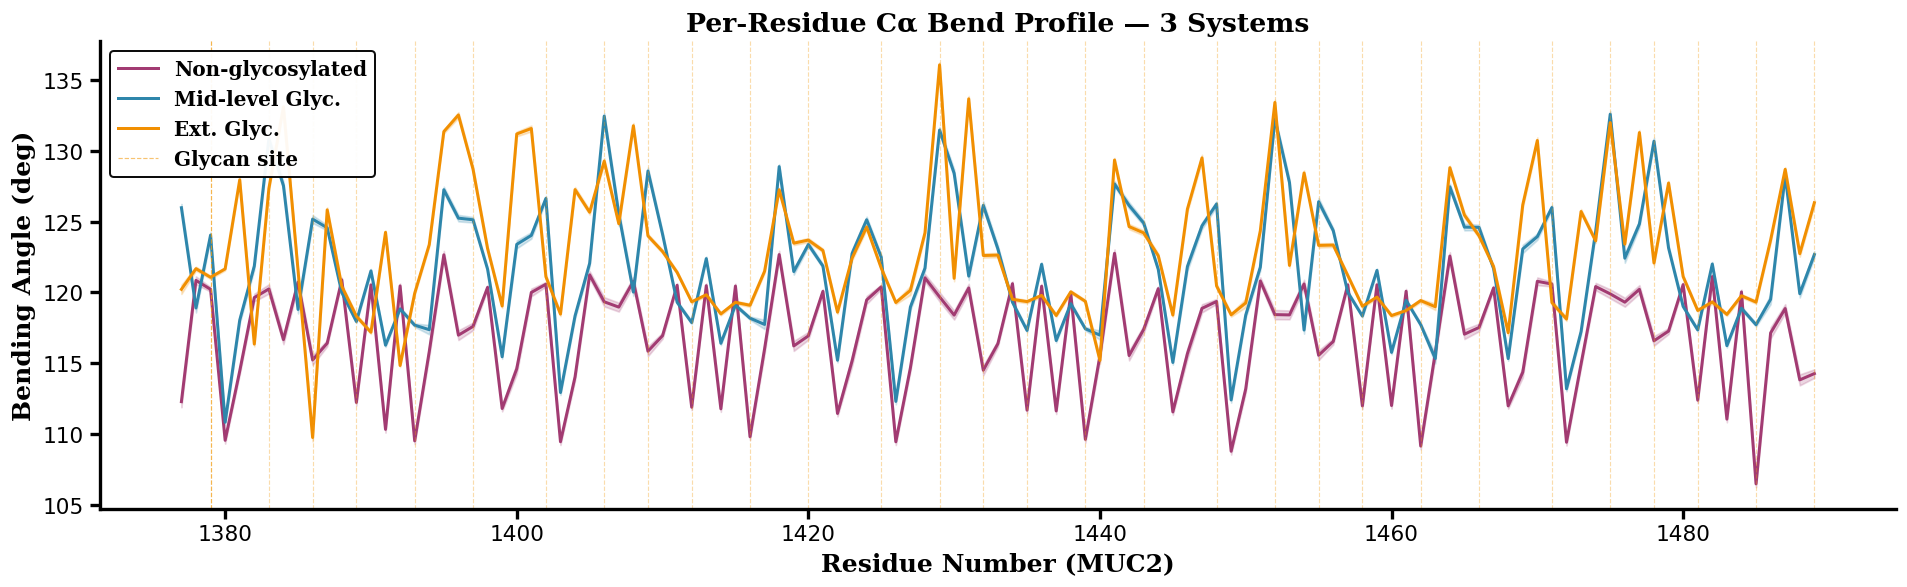

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/bend_profile_3sys.png


In [6]:
fig, ax = plt.subplots(figsize=(16, 5), dpi=120)
fig.set_facecolor('white')

systems_prof = [
    (bend_nog, se_nog, CLR_NOG, 'Non-glycosylated'),
    (bend_gly, se_gly, CLR_GLY, 'Mid-level Glyc.'),
    (bend_ext, se_ext, CLR_EXT, 'Ext. Glyc.'),
]
for bend, se, clr, lbl in systems_prof:
    ax.plot(res_idx, bend, color=clr, linewidth=1.8, label=lbl)
    ax.fill_between(res_idx, bend-se, bend+se, color=clr, alpha=0.20)

for r in GLYCAN_RES:
    ax.axvline(r, color='#F39C12', linewidth=0.7, linestyle='--', alpha=0.35)
ax.axvline(GLYCAN_RES[0], color='#F39C12', linewidth=0.7, linestyle='--',
           alpha=0.6, label='Glycan site')

ax.set_xlabel('Residue Number (MUC2)', fontsize=15, fontname='DejaVu Serif', fontweight='bold')
ax.set_ylabel('Bending Angle (deg)', fontsize=15, fontname='DejaVu Serif', fontweight='bold')
ax.set_title('Per-Residue Cα Bend Profile — 3 Systems', fontsize=16,
             fontname='DejaVu Serif', fontweight='bold')
leg = ax.legend(fontsize=12, framealpha=0.95, edgecolor='black',
                prop={'family':'DejaVu Serif','size':12,'weight':'bold'})
leg.get_frame().set_linewidth(1.2)
ax.set_facecolor('white')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
ax.tick_params(labelsize=13, length=6, width=2.0, direction='out')
plt.tight_layout()
out = OUT_DIR + 'bend_profile_3sys.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)

---
## Part C — Total Bend vs. Overall Chain Dimensions
Test the claim: *"redistributing local bends WITHOUT changing overall chain dimensions."*
If total summed bending is similar across glycoforms while Rg differs, the claim holds.

Total summed bending angle (deg) across all residues:
  Non-glycosylated : 13197.37
  Mid-level Glyc.  : 13747.63
  Ext. Glyc.       : 13901.90

Difference Ext-NoG: 704.54 deg
Difference Gly-NoG: 550.27 deg


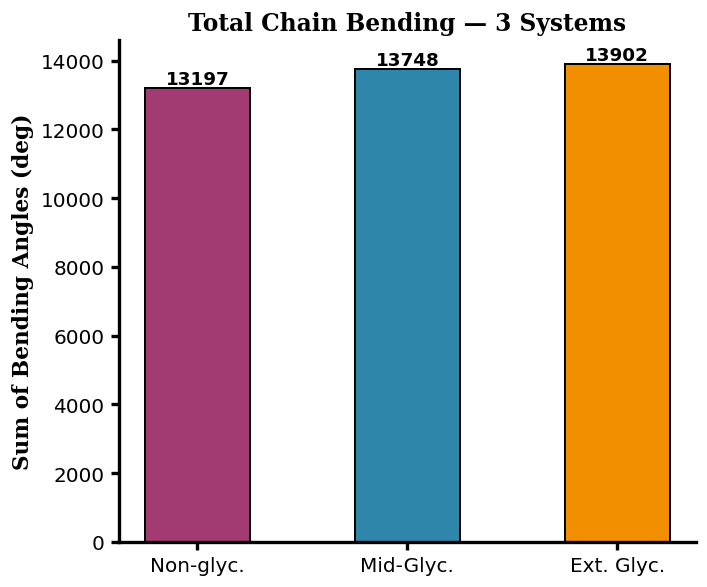

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/total_bend_bar.png


In [7]:
total_nog = bend_nog.sum()
total_gly = bend_gly.sum()
total_ext = bend_ext.sum()

print('Total summed bending angle (deg) across all residues:')
print(f'  Non-glycosylated : {total_nog:.2f}')
print(f'  Mid-level Glyc.  : {total_gly:.2f}')
print(f'  Ext. Glyc.       : {total_ext:.2f}')
print(f'\nDifference Ext-NoG: {total_ext - total_nog:.2f} deg')
print(f'Difference Gly-NoG: {total_gly - total_nog:.2f} deg')

# Bar chart
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
fig.set_facecolor('white')
labels = ['Non-glyc.', 'Mid-Glyc.', 'Ext. Glyc.']
totals = [total_nog, total_gly, total_ext]
colors = [CLR_NOG, CLR_GLY, CLR_EXT]
bars = ax.bar(labels, totals, color=colors, width=0.5, edgecolor='black', linewidth=1.2)
ax.set_ylabel('Sum of Bending Angles (deg)', fontsize=13, fontname='DejaVu Serif', fontweight='bold')
ax.set_title('Total Chain Bending — 3 Systems', fontsize=14,
             fontname='DejaVu Serif', fontweight='bold')
for bar, val in zip(bars, totals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 5, f'{val:.0f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_facecolor('white')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
ax.tick_params(labelsize=12, length=5, width=2.0)
plt.tight_layout()
out = OUT_DIR + 'total_bend_bar.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)

---
## Part D — Bend Redistribution: Correlate Per-Residue Bend with PC2
Load PC2 scores per frame, then for each residue compute Pearson r(bend_i, PC2).
A mix of +/− peaks along the sequence = quantitative evidence of redistribution.

In [8]:
# Load PCA projections (PC1, PC2, system label)
pca_df = pd.read_csv(PCA_FILE, sep=r'\s+', comment='#',
                     names=['PC1', 'PC2', 'system'])
print('Total frames:', len(pca_df))
print(pca_df['system'].value_counts())

pc2_nog = pca_df[pca_df['system'] == 'noglycans']['PC2'].values
pc2_gly = pca_df[pca_df['system'] == 'glycans']['PC2'].values
print(f'\nNoGlyc PC2 frames: {len(pc2_nog)}   MidGlyc PC2 frames: {len(pc2_gly)}')

Total frames: 4886
glycans      2505
noglycans    2381
Name: system, dtype: int64

NoGlyc PC2 frames: 2381   MidGlyc PC2 frames: 2505


In [9]:
# Load per-frame bending angle data
# Columns: frame_index, kappa_rms_rad, kappa_rms_deg
# NOTE: these are overall RMS bending angles (scalar per frame).
# For per-RESIDUE × per-frame bend we need the full trajectory.
# This cell uses the available scalar-per-frame data as a proxy:
# correlating overall RMS bend with PC2 as a first check.

nog_frame = np.genfromtxt(CURV_DIR + 'bending_angle_perframe_noglycans.dat', comments='#')
gly_frame = np.genfromtxt(CURV_DIR + 'bending_angle_perframe_glycans.dat',   comments='#')

# Align frame counts
n_nog = min(len(nog_frame), len(pc2_nog))
n_gly = min(len(gly_frame), len(pc2_gly))

r_nog = np.corrcoef(nog_frame[:n_nog, 2], pc2_nog[:n_nog])[0, 1]
r_gly = np.corrcoef(gly_frame[:n_gly, 2], pc2_gly[:n_gly])[0, 1]

print(f'Pearson r (overall bend vs PC2):')
print(f'  Non-glycosylated : r = {r_nog:.4f}')
print(f'  Mid-level Glyc.  : r = {r_gly:.4f}')

Pearson r (overall bend vs PC2):
  Non-glycosylated : r = -0.0377
  Mid-level Glyc.  : r = -0.0426


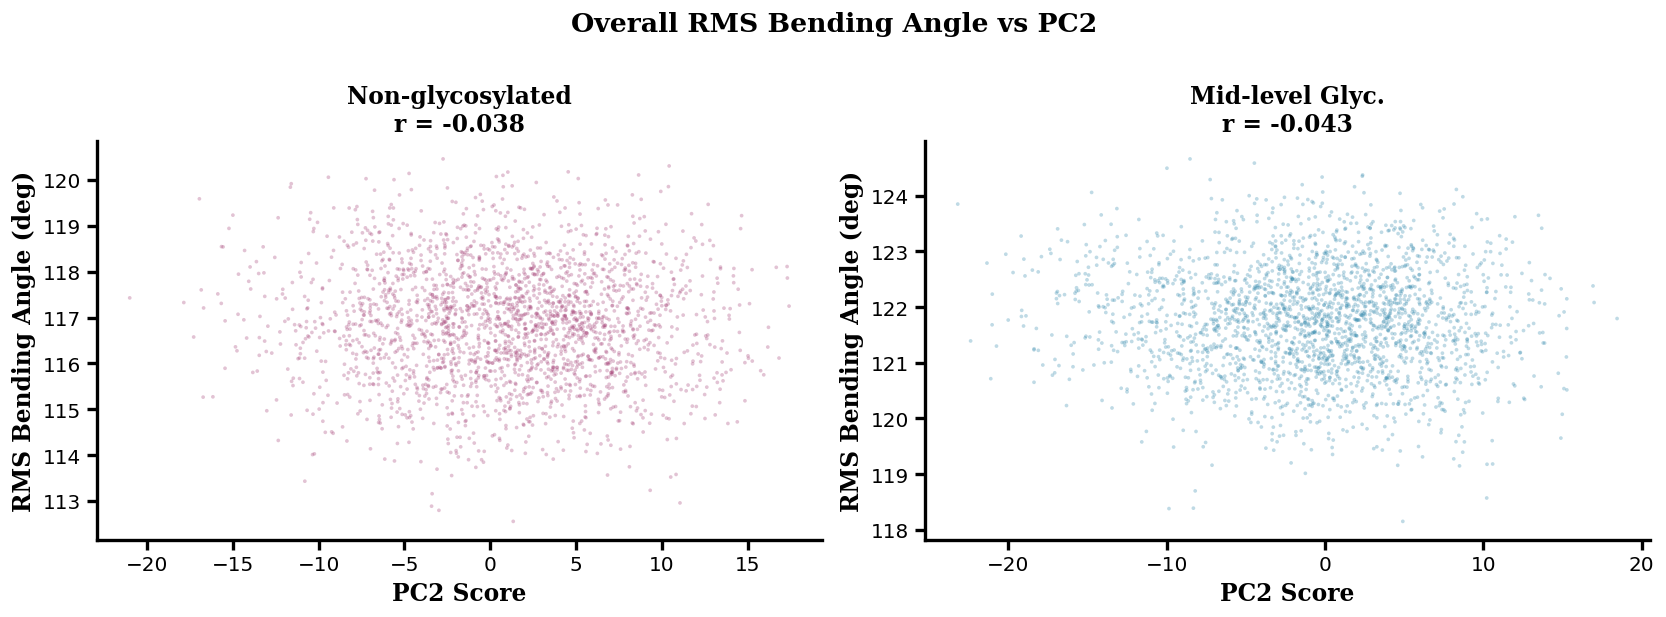

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/bend_vs_pc2_scatter.png


In [10]:
# Scatter: overall RMS bending angle vs PC2 per frame
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)
fig.set_facecolor('white')

for ax, (bend_f, pc2, clr, lbl, r) in zip(axes, [
    (nog_frame[:n_nog, 2], pc2_nog[:n_nog], CLR_NOG, 'Non-glycosylated', r_nog),
    (gly_frame[:n_gly, 2], pc2_gly[:n_gly], CLR_GLY, 'Mid-level Glyc.', r_gly),
]):
    ax.scatter(pc2, bend_f, c=clr, s=5, alpha=0.3, edgecolors='none')
    ax.set_xlabel('PC2 Score', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
    ax.set_ylabel('RMS Bending Angle (deg)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
    ax.set_title(f'{lbl}\nr = {r:.3f}', fontsize=14,
                 fontname='DejaVu Serif', fontweight='bold')
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
    ax.tick_params(labelsize=12, length=6, width=2.0, direction='out')

fig.suptitle('Overall RMS Bending Angle vs PC2', fontsize=16,
             fontname='DejaVu Serif', fontweight='bold', y=1.02)
plt.tight_layout()
out = OUT_DIR + 'bend_vs_pc2_scatter.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)

In [11]:
# Per-residue bend vs PC2 correlation using mean profile differences
# as a proxy for the redistribution test (requires full per-residue/frame data for full test).
# Here: compute delta_bend(residue) = bend_gly - bend_nog and check if it anti-correlates
# (some residues more bent in glyc, others less = redistribution signature).

delta_gly_nog = bend_gly - bend_nog
delta_ext_nog = bend_ext - bend_nog
delta_ext_gly = bend_ext - bend_gly

n_pos_gly = (delta_gly_nog > 0).sum()
n_neg_gly = (delta_gly_nog < 0).sum()
n_pos_ext = (delta_ext_nog > 0).sum()
n_neg_ext = (delta_ext_nog < 0).sum()

print('Δbend (Glyc − NoGlyc):')
print(f'  Residues more bent in Glyc  (+): {n_pos_gly}')
print(f'  Residues less bent in Glyc  (−): {n_neg_gly}')
print(f'  Net Δ: {delta_gly_nog.sum():.2f} deg')
print(f'\nΔbend (ExtGlyc − NoGlyc):')
print(f'  Residues more bent in ExtGlyc (+): {n_pos_ext}')
print(f'  Residues less bent in ExtGlyc (−): {n_neg_ext}')
print(f'  Net Δ: {delta_ext_nog.sum():.2f} deg')

Δbend (Glyc − NoGlyc):
  Residues more bent in Glyc  (+): 98
  Residues less bent in Glyc  (−): 15
  Net Δ: 550.27 deg

Δbend (ExtGlyc − NoGlyc):
  Residues more bent in ExtGlyc (+): 98
  Residues less bent in ExtGlyc (−): 15
  Net Δ: 704.54 deg


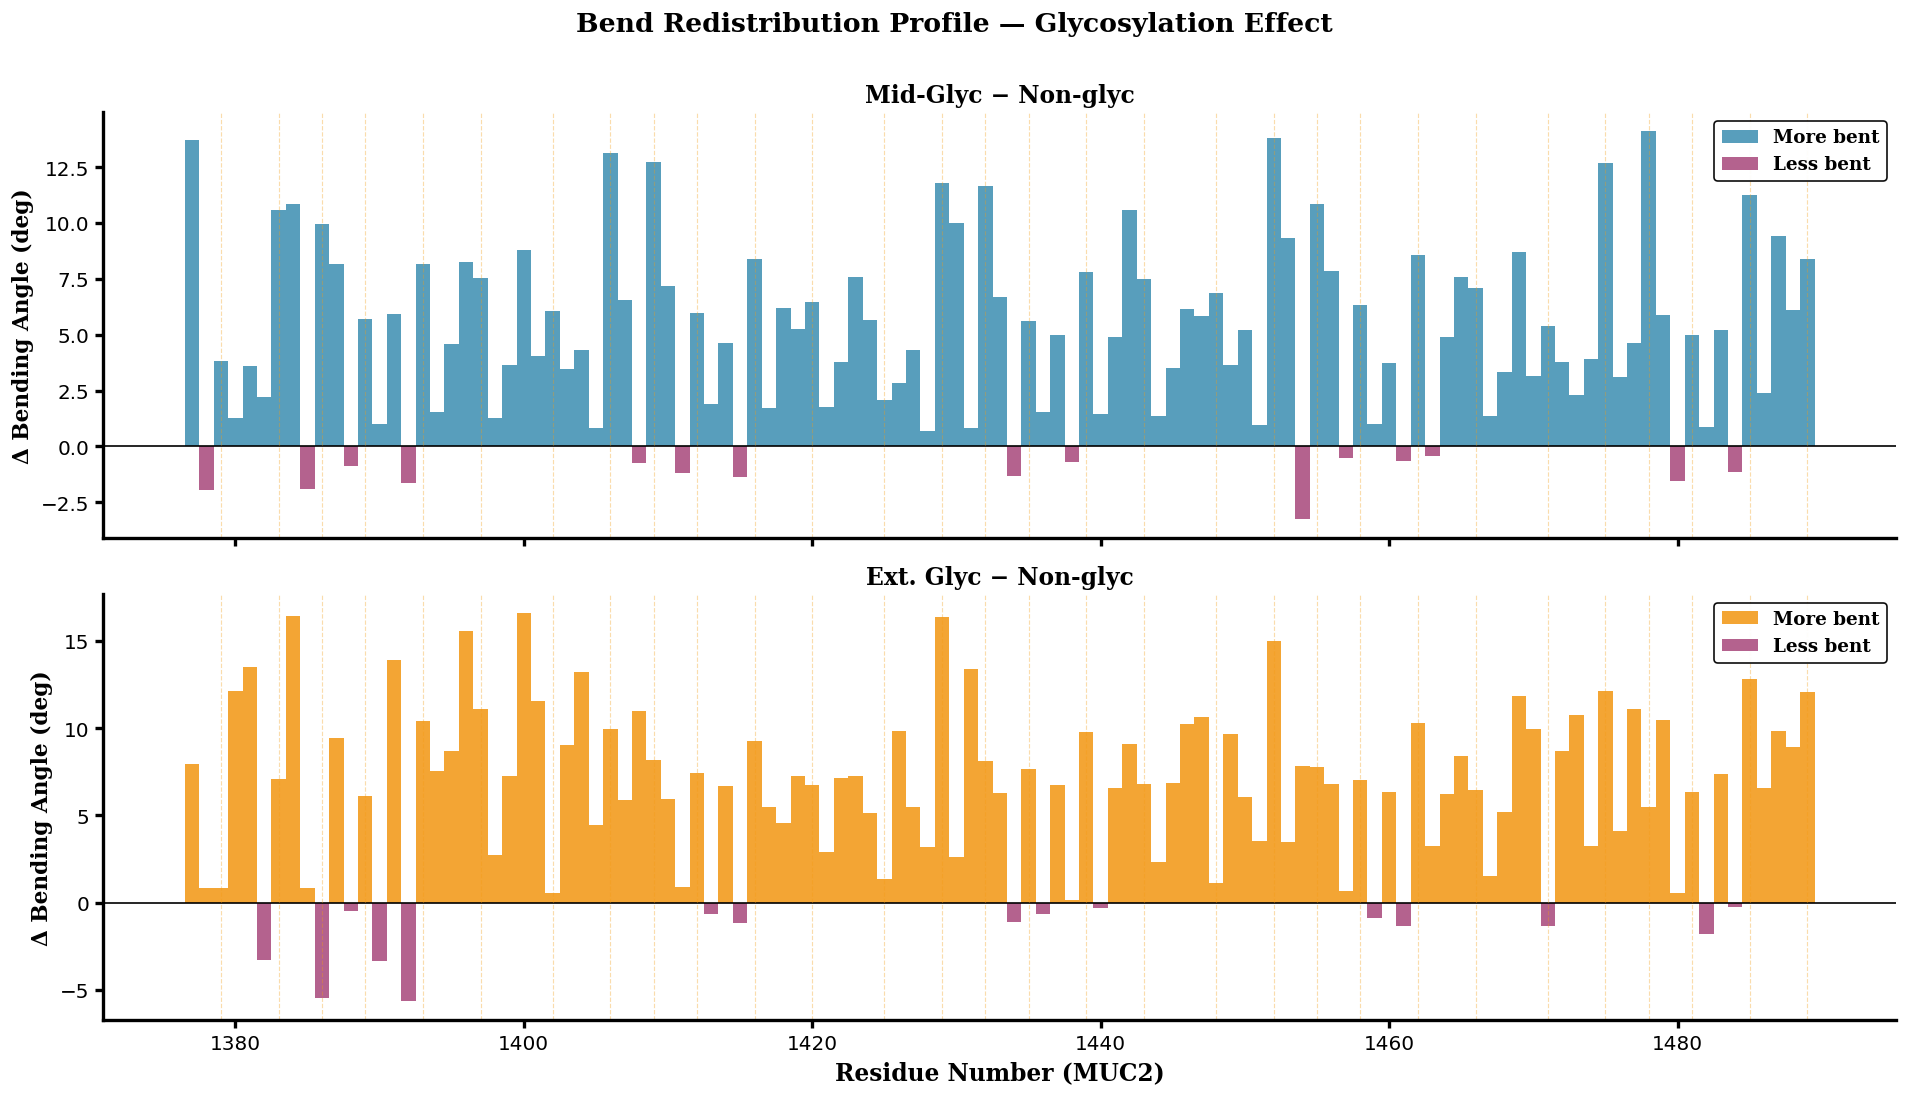

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/bend_redistribution_profile.png

A mix of + and − bars = bending is REDISTRIBUTED along the sequence, not uniformly increased.


In [12]:
# Redistribution profile plot — shows WHERE along sequence bends shift
fig, axes = plt.subplots(2, 1, figsize=(16, 9), dpi=120, sharex=True)
fig.set_facecolor('white')

pairs = [
    (delta_gly_nog, CLR_GLY, 'Mid-Glyc − Non-glyc'),
    (delta_ext_nog, CLR_EXT, 'Ext. Glyc − Non-glyc'),
]
for ax, (delta, clr, lbl) in zip(axes, pairs):
    pos = np.where(delta > 0, delta, 0)
    neg = np.where(delta < 0, delta, 0)
    ax.bar(res_idx, pos, color=clr,    width=1.0, alpha=0.80, label='More bent')
    ax.bar(res_idx, neg, color=CLR_NOG, width=1.0, alpha=0.80, label='Less bent')
    ax.axhline(0, color='black', linewidth=1.0)
    for r in GLYCAN_RES:
        ax.axvline(r, color='#F39C12', linewidth=0.7, linestyle='--', alpha=0.35)
    ax.set_ylabel('Δ Bending Angle (deg)', fontsize=13, fontname='DejaVu Serif', fontweight='bold')
    ax.set_title(lbl, fontsize=14, fontname='DejaVu Serif', fontweight='bold')
    ax.legend(fontsize=11, framealpha=0.95, edgecolor='black',
              prop={'family':'DejaVu Serif','size':11,'weight':'bold'})
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
    ax.tick_params(labelsize=12, length=5, width=2.0, direction='out')

axes[-1].set_xlabel('Residue Number (MUC2)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
fig.suptitle('Bend Redistribution Profile — Glycosylation Effect',
             fontsize=16, fontname='DejaVu Serif', fontweight='bold', y=1.01)
plt.tight_layout()
out = OUT_DIR + 'bend_redistribution_profile.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)
print('\nA mix of + and − bars = bending is REDISTRIBUTED along the sequence, not uniformly increased.')

---
## Part E — Twist Angle (Cα Dihedral) Profile
Compute the virtual Cα dihedral angle from the mean structures.
This tests the **twisting hypothesis**: whether PC2 captures backbone twist (rotation about chain axis)
in addition to in-plane bending.

For full per-frame twist vs PC2 correlation, mdtraj + trajectory files are required (see Step 5 in strategy).
This cell computes the twist profile from mean structures as a starting point.

In [13]:
def compute_ca_twist(pdb_path):
    """Compute virtual Cα dihedral (twist) for each quadruplet of consecutive Cα atoms."""
    resnums, coords = parse_ca_from_pdb(pdb_path)
    twists, res = [], []
    for i in range(len(coords) - 3):
        p0, p1, p2, p3 = coords[i], coords[i+1], coords[i+2], coords[i+3]
        twist = dihedral(p0, p1, p2, p3)
        twists.append(twist)
        res.append(resnums[i+1])   # anchor at second residue
    return np.array(twists), np.array(res)

twist_data = {}
for name, pdb, clr in systems_pdb:
    tw, res = compute_ca_twist(pdb)
    twist_data[name] = (tw, res, clr)
    print(f'{name}: {len(tw)} twist angles  mean={tw.mean():.1f}°  std={tw.std():.1f}°')

Non-glycosylated: 112 twist angles  mean=69.6°  std=91.5°
Mid-level Glyc.: 112 twist angles  mean=92.2°  std=77.9°
Ext. Glyc.: 112 twist angles  mean=76.5°  std=90.1°


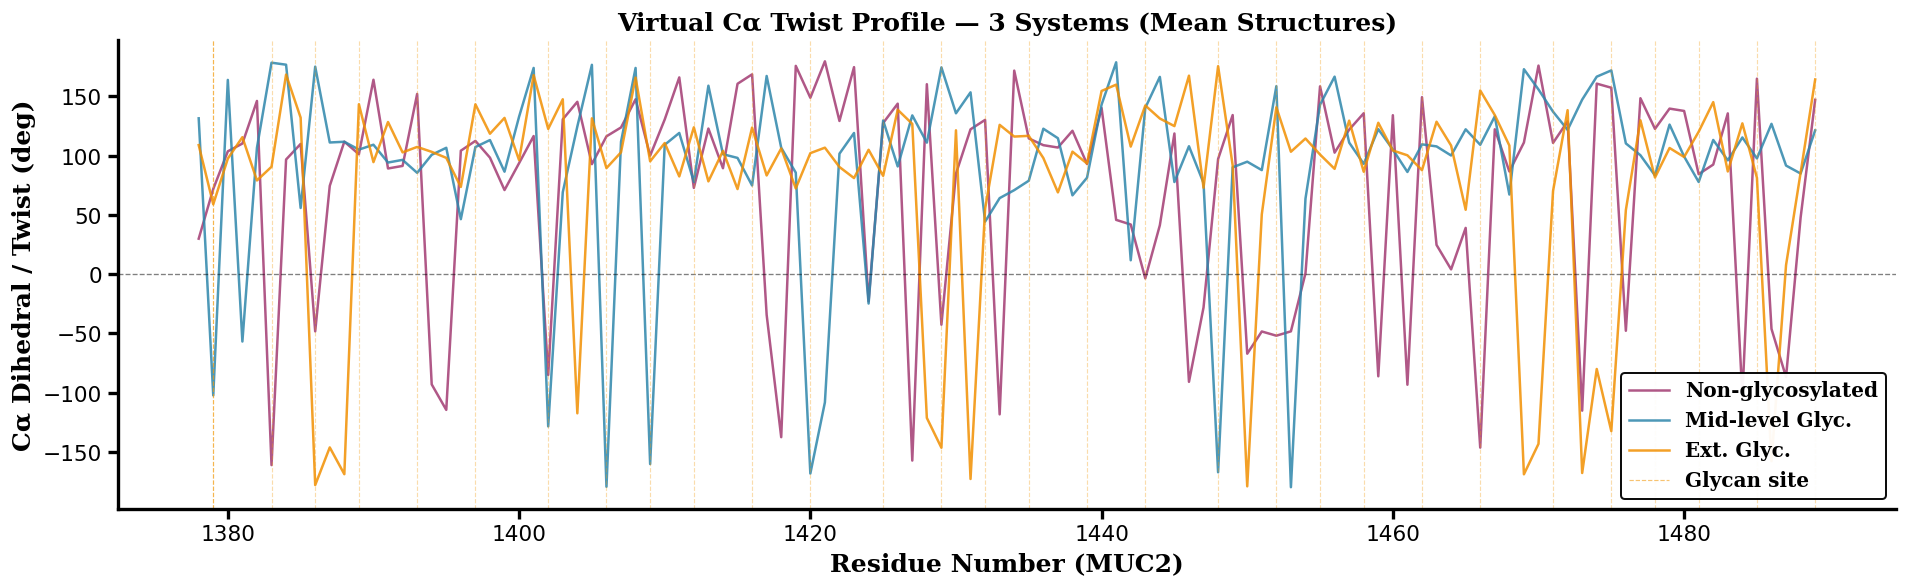

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/ca_twist_profile.png


In [14]:
fig, ax = plt.subplots(figsize=(16, 5), dpi=120)
fig.set_facecolor('white')

for name, pdb, clr in systems_pdb:
    tw, res, clr = twist_data[name]
    ax.plot(res, tw, color=clr, linewidth=1.5, alpha=0.85, label=name)

ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
for r in GLYCAN_RES:
    ax.axvline(r, color='#F39C12', linewidth=0.7, linestyle='--', alpha=0.35)
ax.axvline(GLYCAN_RES[0], color='#F39C12', linewidth=0.7, linestyle='--',
           alpha=0.6, label='Glycan site')

ax.set_xlabel('Residue Number (MUC2)', fontsize=15, fontname='DejaVu Serif', fontweight='bold')
ax.set_ylabel('Cα Dihedral / Twist (deg)', fontsize=15, fontname='DejaVu Serif', fontweight='bold')
ax.set_title('Virtual Cα Twist Profile — 3 Systems (Mean Structures)',
             fontsize=15, fontname='DejaVu Serif', fontweight='bold')
leg = ax.legend(fontsize=12, framealpha=0.95, edgecolor='black',
                prop={'family':'DejaVu Serif','size':12,'weight':'bold'})
leg.get_frame().set_linewidth(1.2)
ax.set_facecolor('white')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
ax.tick_params(labelsize=13, length=6, width=2.0, direction='out')
plt.tight_layout()
out = OUT_DIR + 'ca_twist_profile.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)

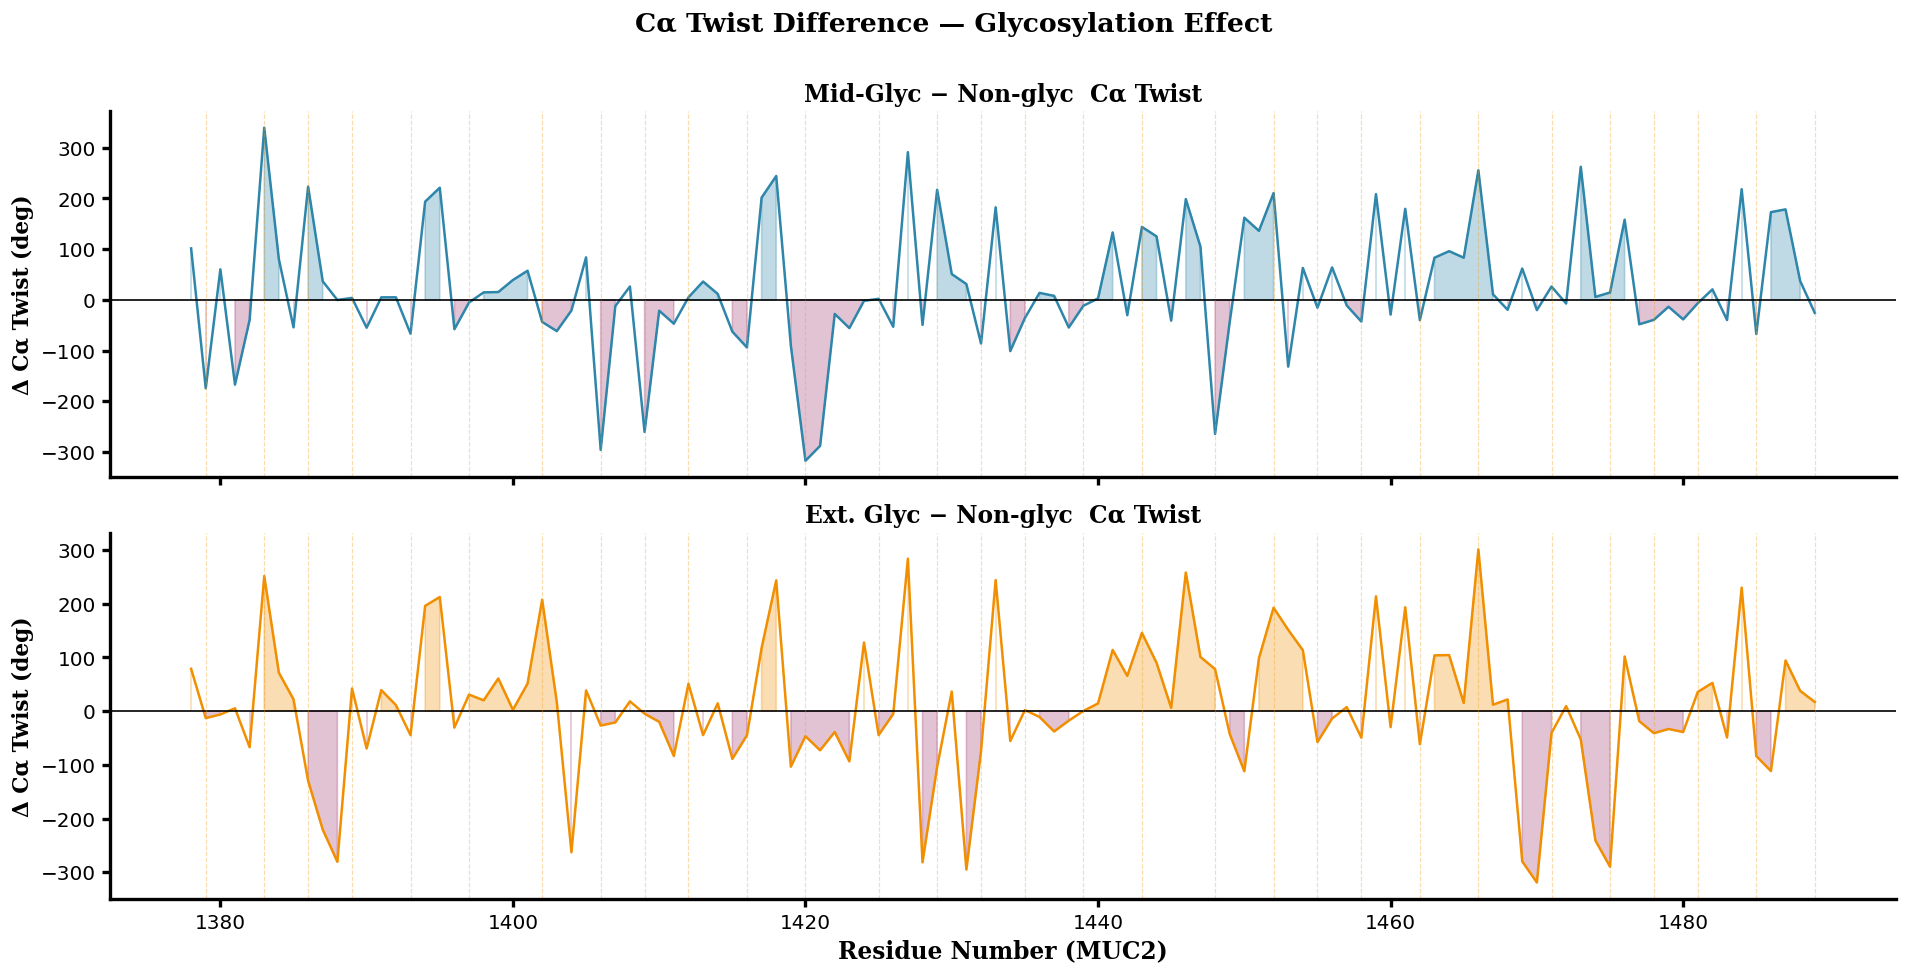

Saved: /home/computer2/analysis_simulations/analysis/phi_psi_bend_plots/ca_twist_difference.png


In [15]:
# Twist difference profiles (glycosylation effect on local twist)
tw_nog = twist_data['Non-glycosylated'][0]
tw_gly = twist_data['Mid-level Glyc.'][0]
tw_ext = twist_data['Ext. Glyc.'][0]
res_tw = twist_data['Non-glycosylated'][1]

n_common = min(len(tw_nog), len(tw_gly), len(tw_ext))
delta_tw_gly = tw_gly[:n_common] - tw_nog[:n_common]
delta_tw_ext = tw_ext[:n_common] - tw_nog[:n_common]

fig, axes = plt.subplots(2, 1, figsize=(16, 8), dpi=120, sharex=True)
fig.set_facecolor('white')
for ax, (delta, clr, lbl) in zip(axes, [
    (delta_tw_gly, CLR_GLY, 'Mid-Glyc − Non-glyc  Cα Twist'),
    (delta_tw_ext, CLR_EXT, 'Ext. Glyc − Non-glyc  Cα Twist'),
]):
    ax.plot(res_tw[:n_common], delta, color=clr, linewidth=1.5)
    ax.fill_between(res_tw[:n_common], delta, 0,
                    where=delta>0, color=clr,    alpha=0.30)
    ax.fill_between(res_tw[:n_common], delta, 0,
                    where=delta<0, color=CLR_NOG, alpha=0.30)
    ax.axhline(0, color='black', linewidth=1.0)
    for r in GLYCAN_RES:
        ax.axvline(r, color='#F39C12', linewidth=0.7, linestyle='--', alpha=0.35)
    ax.set_ylabel('Δ Cα Twist (deg)', fontsize=13, fontname='DejaVu Serif', fontweight='bold')
    ax.set_title(lbl, fontsize=14, fontname='DejaVu Serif', fontweight='bold')
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
    ax.tick_params(labelsize=12, length=5, width=2.0, direction='out')

axes[-1].set_xlabel('Residue Number (MUC2)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
fig.suptitle('Cα Twist Difference — Glycosylation Effect',
             fontsize=16, fontname='DejaVu Serif', fontweight='bold', y=1.01)
plt.tight_layout()
out = OUT_DIR + 'ca_twist_difference.png'
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', out)

---
## Part E (Full) — Per-Frame Twist vs PC2 Correlation
Requires `mdtraj` and the full aligned trajectory. Install with:
```bash
pip install mdtraj
```
Then run this cell to get the per-residue twist × PC2 correlation profile — the quantitative test of the twisting hypothesis.

In [16]:
# ── Requires mdtraj ──────────────────────────────────────────────────────────
try:
    import mdtraj as md
    MDTRAJ_AVAILABLE = True
except ImportError:
    MDTRAJ_AVAILABLE = False
    print('mdtraj not installed. Run:  pip install mdtraj')
    print('Then re-run this cell.')

if MDTRAJ_AVAILABLE:
    XTC_FILE = '/home/computer2/analysis_simulations/analysis/physical_variables/longpts_combined_aligned.xtc'
    TOP_FILE = ''   # ← fill in path to topology (.prmtop or .pdb)

    if not TOP_FILE:
        print('Set TOP_FILE to your topology file path and re-run.')
    else:
        traj = md.load(XTC_FILE, top=TOP_FILE)
        ca_idx = traj.topology.select('name CA')
        quads  = np.array([[ca_idx[i], ca_idx[i+1], ca_idx[i+2], ca_idx[i+3]]
                           for i in range(len(ca_idx)-3)])
        twist_traj = md.compute_dihedrals(traj, quads) * 180 / np.pi
        # twist_traj.shape = (n_frames, n_residues-3)

        # Correlate each residue's twist with PC2
        # (align frames to PC2 scores from pca_coords_justlongpts.dat)
        pc2_all = pca_df['PC2'].values[:len(traj)]
        twist_corr = np.array([np.corrcoef(twist_traj[:, i], pc2_all)[0, 1]
                               for i in range(twist_traj.shape[1])])

        fig, ax = plt.subplots(figsize=(16, 4), dpi=120)
        fig.set_facecolor('white')
        res_tw_all = [r + RES_OFFSET for r in range(1, len(twist_corr)+1)]
        ax.bar(res_tw_all, twist_corr, width=1.0,
               color=np.where(np.array(twist_corr) > 0, CLR_GLY, CLR_NOG), alpha=0.8)
        ax.axhline(0, color='black', linewidth=1.0)
        ax.set_xlabel('Residue Number', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
        ax.set_ylabel('Pearson r (twist vs PC2)', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
        ax.set_title('Per-Residue Cα Twist Correlation with PC2', fontsize=15,
                     fontname='DejaVu Serif', fontweight='bold')
        plt.tight_layout()
        out = OUT_DIR + 'twist_pc2_correlation.png'
        plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
        plt.show()
        print('Saved:', out)

mdtraj not installed. Run:  pip install mdtraj
Then re-run this cell.


---
## Summary

| Step | What it tests | Key output |
|------|--------------|------------|
| Part A | φ/ψ Ramachandran scatter from mean structures | `ramachandran_3sys.png` |
| Part B | Per-residue Cα bend profile across glycoforms | `bend_profile_3sys.png` |
| Part C | Total chain bending vs. overall dimensions | `total_bend_bar.png` |
| Part D | Bend redistribution along sequence (Δbend profile) | `bend_redistribution_profile.png` |
| Part E | Cα twist profile and Δtwist (mean structures) | `ca_twist_profile.png`, `ca_twist_difference.png` |
| Part E (full) | Per-residue twist × PC2 correlation (needs mdtraj) | `twist_pc2_correlation.png` |

**Interpretation guide:**
- If `bend_redistribution_profile.png` shows a mix of + and − bars → bends are *redistributed*, not uniformly added.
- If `total_bend_bar.png` shows similar totals across systems → redistribution claim holds.
- If `ca_twist_difference.png` shows systematic shifts → twisting hypothesis supported; run Part E (full) to quantify.